In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
import random
from tqdm.notebook import tqdm
import seaborn as sns
from qpsolvers import solve_qp
from itertools import product
from skophys.preprocessing import Vectorizer, UnVectorizer
import tifffile
import scipy

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.
/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

# Top left corner of movie

In [3]:
movie = tifffile.imread("/home/kushal/caiman_data/example_movies/demoMovie.tif")[:, :40, :50]
movie.shape

(2000, 40, 50)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
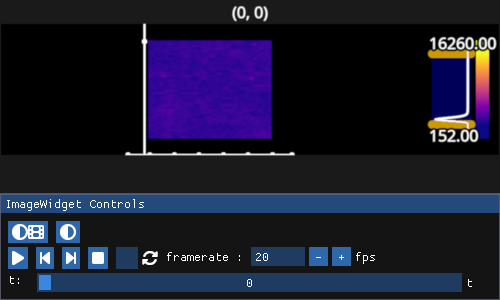

In [4]:
iw_movie = fpl.ImageWidget(movie)
iw_movie.show()

In [5]:
from skimage.transform import downscale_local_mean

# Subsample movie

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
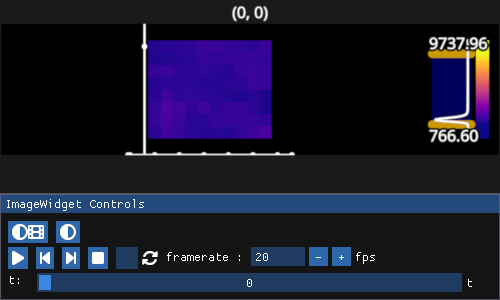

In [56]:
movie_sub = downscale_local_mean(movie, factors=(1, 5, 5))
fpl.ImageWidget(movie_sub).show()

In [57]:
def sim_matching_init(X_init, k, error_stop, eta=1e-1) -> tuple[np.ndarray, np.ndarray, int]:
    """
    Returns
    -------
        W, M, n_iter
    """
    cov = X_init.T @ X_init
    XTX = cov / np.linalg.norm(cov, ord="fro")
    
    T = XTX.shape[0]
    
    Y = (np.random.randn(k, T) / np.sqrt(T)).clip(0)

    error_log = np.zeros(20_000)
    error_log[:] = np.nan

    for n_iter in tqdm(range(20_000)):
        Y_old = Y
        Y = Y + eta * Y @ (XTX - Y.T @ Y)
        
        zeroed = Y.sum(axis=1) == 0.0
        Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
        
        # Y = Y.clip(0)
    
        er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
        error_log[n_iter] = er
    
        if er < error_stop:
            break
            
    W = Y @ X_init.T
    M = Y @ Y.T

    return Y, W, M, n_iter, error_log

# Vectorize

In [58]:
unvec = UnVectorizer(movie_sub.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie_sub)

In [59]:
X.shape

(80, 2000)

In [60]:
n_pixels = X.shape[0]

In [61]:
lag = 4
lag_step = 1

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

In [62]:
H.shape

(640, 1993)

In [63]:
mu0 = H[:lag * n_pixels].mean(axis=1)
mu1 = H[lag * n_pixels:].mean(axis=1)

In [64]:
H[:lag * n_pixels] -= mu0[:, None]
H[lag * n_pixels:] -= mu1[:, None]

In [65]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

# k: number of components

In [66]:
k = 5

# list of slices of lags, each slice is the indices in `W` that represent pixels for one lag time

In [67]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag * 2)]
lag_slices

[slice(0, 80, None),
 slice(80, 160, None),
 slice(160, 240, None),
 slice(240, 320, None),
 slice(320, 400, None),
 slice(400, 480, None),
 slice(480, 560, None),
 slice(560, 640, None)]

In [68]:
H = np.vstack(
    [
        scipy.linalg.pinv(scipy.linalg.sqrtm(past @ past.T / past.shape[1])) @ past,
        scipy.linalg.pinv(scipy.linalg.sqrtm(future @ future.T / future.shape[1])) @ past,
    ]
)

In [69]:
from itertools import product

# Offline sim matching and plot

Run this and every ~5 tries you may get something that resembles 2 of the neurons

  0%|          | 0/20000 [00:00<?, ?it/s]

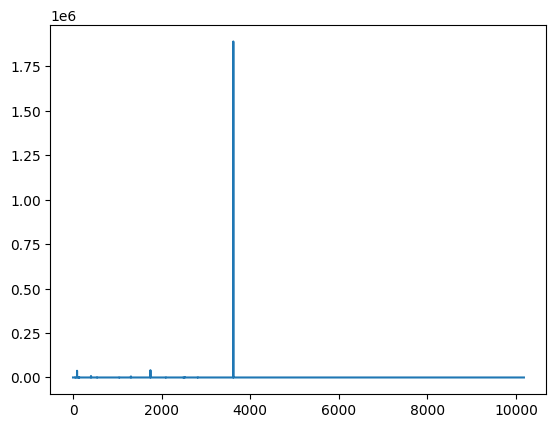

In [70]:
Y, W, M, n_iter, errors = sim_matching_init(H, k, error_stop=1e-4, eta=5e-1)

plt.plot(errors)
plt.show()

In [71]:
lag_slices

[slice(0, 80, None),
 slice(80, 160, None),
 slice(160, 240, None),
 slice(240, 320, None),
 slice(320, 400, None),
 slice(400, 480, None),
 slice(480, 560, None),
 slice(560, 640, None)]

RFBOutputContext()

JupyterRenderCanvas(css_height='600.0px', css_width='1200.0px')
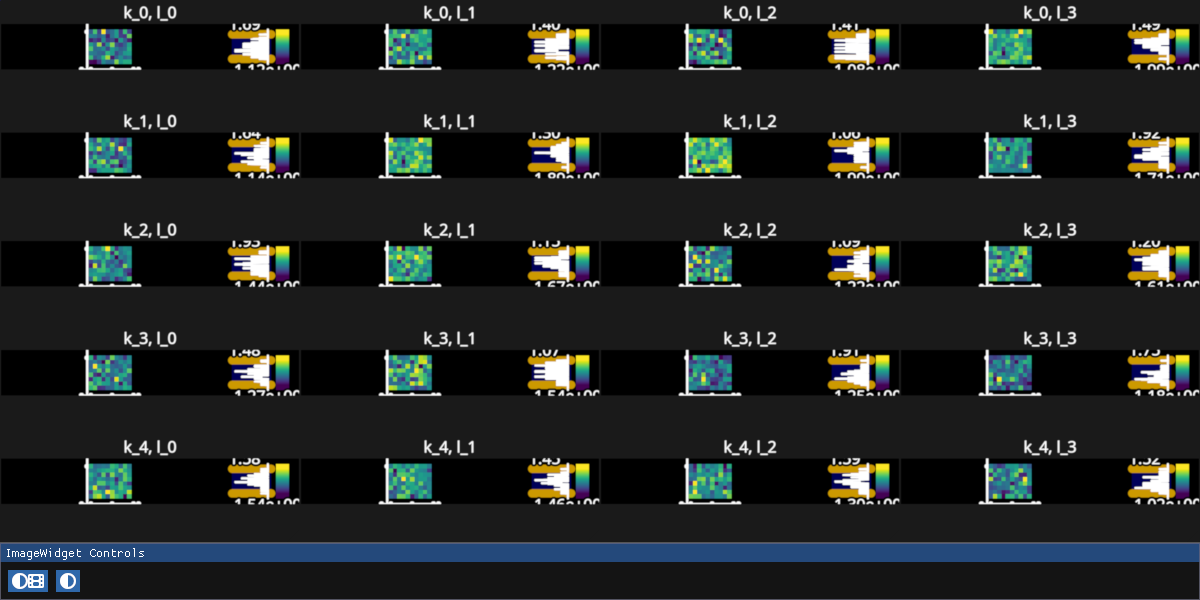

In [72]:
# make images by reshaing each lag within `W`
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(W[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (1200, 600)},
)
iw_W.show()

In [54]:
Y.shape

(5, 1993)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
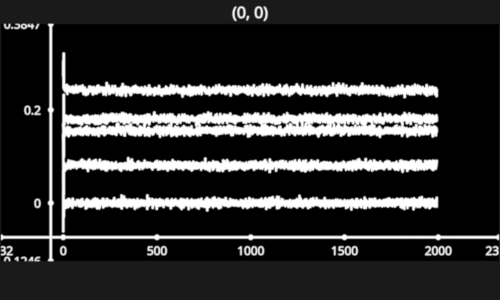

In [55]:
fig = fpl.Figure()

fig[0, 0].add_line_stack(Y, separation=0.01)

fig.show(maintain_aspect=False)

# flip cmap if necessary

In [182]:
iw_W.cmap = "viridis"

In [177]:
def solve_yt(x_t, Wt, Mt, k):
    return solve_qp(
        (Mt + Mt.T) / 2,
        -Wt @ x_t,
        lb=np.zeros(k),
        solver="cvxopt"
    )

In [178]:
X_diag = np.diag(np.ones(H.shape[0]))

F = np.zeros((k, H.shape[0]))

for i in range(H.shape[0]):
    F[:, i] = solve_yt(X_diag[:, i], W, M, k)

F /= F.sum(axis=1)[:, None]

In [179]:
F.shape

(5, 1040)

In [180]:
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(F[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

RFBOutputContext()

JupyterRenderCanvas(css_height='600.0px', css_width='1200.0px')
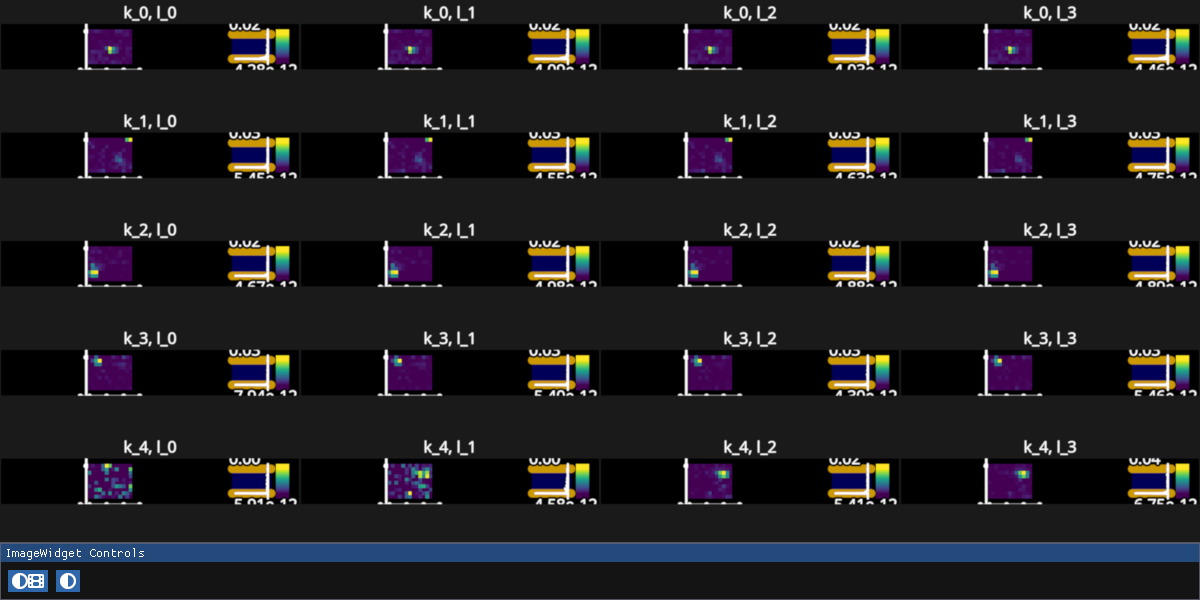

In [181]:
fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (1200, 600)},
).show()